# WebShield — Automated Web Security Analysis & Experimental Evaluation
### Final-Year Cybersecurity Capstone Engineering Demonstration

---

## Abstract & Executive Summary
Modern web applications rely heavily on browser-enforced security mechanisms. While custom backend code and database queries often receive the primary focus of security testing, fundamental vulnerabilities frequently arise from missing or misconfigured transport layers, HTTP defense headers, permissive Cross-Origin Resource Sharing (CORS) policies, and insecure session cookie attributes.

**WebShield** is an automated, non-destructive web security scanner engineered to assess external security configurations safely. This Jupyter Notebook serves as an experimental demonstration and technical validation of the WebShield engine.

### Notebook Objectives:
1. **SSRF Mitigation & Boundary Defense:** Validate that WebShield strictly denies private IP ranges, loopback endpoints, cloud metadata targets, and obfuscated numeric encodings *prior* to network socket creation.
2. **Modular Inspection Verification:** Exercise the modular security engines for **HTTP Defense Headers**, **Cookie Attributes**, **CORS Controls**, and **HTML Form Practices**.
3. **Controlled Simulation & Testing:** Execute a full scan cycle against an ephemeral, controlled local HTTP mock server without requiring external network access or MySQL configuration.
4. **Post-Scan Telemetry & Visualizations:** Tabulate findings using `pandas` and render security score benchmarks and severity breakdowns using `matplotlib`.
5. **Report Generation:** Demonstrate structured JSON export capabilities for DevSecOps pipeline integration.

> **Ethical Scanner Notice:** All live scans must only be directed at systems you own or have explicit written authorization to assess. WebShield implements strict pre-flight SSRF guardrails and enforces TLS certificate verification.


## 1. Environment Setup & Scanner Module Loading

In this section, we configure the Python runtime environment, add the WebShield project root to `sys.path`, and import the actual production scanner modules from `scanner/`:
- `scanner.safety`: Pre-flight URL normalization, SSRF filtering, and redirect validation.
- `scanner.headers`: HTTP defense header evaluations (CSP, HSTS, XFO, XCTO, etc.).
- `scanner.cookies`: Session token and tracking cookie security flag analyzer (`Secure`, `HttpOnly`, `SameSite`).
- `scanner.cors`: Cross-Origin Resource Sharing origin reflection and credential checks.
- `scanner.html_checks`: DOM inspection for plaintext forms and password field attributes.
- `scanner.transport`: HTTPS support, TLS certificate validation, and redirect analysis.
- `scanner.scoring`: Deductive scoring algorithm and qualitative rating categories.


In [1]:
import sys
import os
from pathlib import Path
import json
import socket
import threading
import http.server

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Data science & visualization libraries
import pandas as pd
import matplotlib.pyplot as plt

# WebShield core scanner modules
from scanner.safety import validate_url, validate_redirect, _is_blocked_ip
from scanner.headers import run_header_checks
from scanner.cookies import run_cookie_checks
from scanner.cors import run_cors_checks
from scanner.html_checks import run_html_checks
from scanner.transport import run_transport_checks
from scanner.scoring import calculate_score, score_label, score_colour, DEDUCTIONS

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans, Arial, Helvetica"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10

print("[+] WebShield scanner modules successfully loaded from:", PROJECT_ROOT)
print(f"[+] Python runtime version: {sys.version.split()[0]}")
print(f"[+] Pandas version: {pd.__version__}")


C:\Users\Soni Chaudhary\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:109: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


[+] WebShield scanner modules successfully loaded from: D:\
[+] Python runtime version: 3.13.1
[+] Pandas version: 3.0.3


## 2. Experiment 1: Pre-Flight SSRF Protection & Network Boundary Defense

### Objective
Demonstrate how WebShield mitigates **Server-Side Request Forgery (SSRF - CWE-918)** before any network socket is opened.

### Methodology
A web security scanner that accepts user-supplied target URLs is inherently at risk of being manipulated to scan internal networks, loopback daemons, and cloud instance metadata services (e.g., AWS/GCP `169.254.169.254`). 

WebShield enforces **defense-in-depth pre-flight validation** in `scanner/safety.py`:
1. **Scheme Whitelist:** Only `http://` and `https://` are permitted. Protocols such as `file://`, `gopher://`, `ftp://`, and `data:` are blocked immediately.
2. **Direct IP Literal Parsing:** Standard dotted-quad IPv4, bracketed IPv6, and obfuscated decimal/hex integers (e.g., `http://2130706433` -> `127.0.0.1`) are parsed directly using Python's `ipaddress` module and checked against prohibited CIDR ranges before DNS resolution.
3. **Cloud Metadata Protection:** Explicit denial of link-local metadata addresses (`169.254.0.0/16`, `[fd00::]/8`) and metadata hostnames (`metadata.google.internal`).
4. **Pre-Flight DNS Resolution:** Hostnames are resolved to IP addresses via `socket.getaddrinfo`, and every returned address is evaluated against blocked ranges.
5. **No Network Contact:** Blocked targets are rejected during the validation phase; **zero HTTP/TCP requests** are dispatched to unauthorized destinations.


In [2]:
# Define battery of SSRF test targets and benign controls
ssrf_test_vectors = [
    ("Loopback IPv4 (Standard)", "http://127.0.0.1"),
    ("Loopback IPv4 (Subnet Boundary)", "http://127.255.255.255"),
    ("Loopback IPv6", "http://[::1]"),
    ("Private Subnet (RFC 1918 Class A)", "http://10.0.0.1:8080"),
    ("Private Subnet (RFC 1918 Class B)", "http://172.16.5.100"),
    ("Private Subnet (RFC 1918 Class C)", "http://192.168.1.1"),
    ("Carrier-Grade NAT (CGN / RFC 6598)", "http://100.64.0.1"),
    ("AWS/OpenStack Cloud Metadata IP", "http://169.254.169.254/latest/meta-data/"),
    ("GCP Cloud Metadata Hostname", "http://metadata.google.internal"),
    ("Obfuscated Decimal IPv4 Literal (127.0.0.1)", "http://2130706433"),
    ("Obfuscated Hexadecimal IPv4 Literal (127.0.0.1)", "http://0x7f000001"),
    ("Broadcast Address", "http://255.255.255.255"),
    ("Zero Address Network", "http://0.0.0.0"),
    ("Disallowed Protocol (Local File Inclusion)", "file:///etc/passwd"),
    ("Disallowed Protocol (File Transfer)", "ftp://ftp.example.com/dump.sql"),
    ("Disallowed Protocol (Embedded Data URI)", "data:text/html;base64,PHNjcmlwdD4="),
    ("Public Authorized Target (Control)", "https://example.com"),
    ("Allowlist Restricted Domain (Unlisted)", "https://unauthorized-domain.org")
]

configured_allowlist = ["example.com", "authorized-partner.com"]
ssrf_records = []

for category, target_url in ssrf_test_vectors:
    # Use allowlist only for the allowlist test case
    active_allowlist = configured_allowlist if "Allowlist" in category else None
    
    val_res = validate_url(target_url, allowlist=active_allowlist)
    ssrf_records.append({
        "Attack Category / Vector": category,
        "Input URL": target_url,
        "Pre-Flight Validation": "PERMITTED" if val_res.valid else "BLOCKED",
        "Enforcement Action": "HTTP Request Allowed" if val_res.valid else "Pre-Flight Rejection (No Request Sent)",
        "Security Diagnostic": val_res.error if not val_res.valid else "Target verified as public",
        "Resolved Addresses": ", ".join(val_res.resolved_ips) if val_res.resolved_ips else "None"
    })

df_ssrf = pd.DataFrame(ssrf_records)
df_ssrf


,Attack Category / Vector,Input URL,Pre-Flight Validation,Enforcement Action,Security Diagnostic,Resolved Addresses
0,Loopback IPv4 (Standard),http://127.0.0.1,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 127.0.0.1 is in blocked range 127.0.0.0/8,None
1,Loopback IPv4 (Subnet Boundary),http://127.255.255.255,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 127.255.255.255 is in blocked range 127.0.0.0/8,None
2,Loopback IPv6,http://[::1],BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: ::1 is in blocked IPv6 range ::1/128,None
3,Private Subnet (RFC 1918 Class A),http://10.0.0.1:8080,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 10.0.0.1 is in blocked range 10.0.0.0/8,None
4,Private Subnet (RFC 1918 Class B),http://172.16.5.100,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 172.16.5.100 is in blocked range 172.16.0.0/12,None
5,Private Subnet (RFC 1918 Class C),http://192.168.1.1,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 192.168.1.1 is in blocked range 192.168.0.0/16,None
6,Carrier-Grade NAT (CGN / RFC 6598),http://100.64.0.1,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 100.64.0.1 is in blocked range 100.64.0.0/10,None
7,AWS/OpenStack Cloud Metadata IP,http://169.254.169.254/latest/meta-data/,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 169.254.169.254 is in blocked range 169.254.0.0/16,None
8,GCP Cloud Metadata Hostname,http://metadata.google.internal,BLOCKED,Pre-Flight Rejection (No Request Sent),Hostname 'metadata.google.internal' is explicitly blocked.,None
9,Obfuscated Decimal IPv4 Literal (127.0.0.1),http://2130706433,BLOCKED,Pre-Flight Rejection (No Request Sent),IP address target is not allowed: 127.0.0.1 is in blocked range 127.0.0.0/8,None


### Analysis of SSRF Defense Results
- **100% Block Rate on Internal & Metadata Ranges:** All loopback variants, RFC 1918 private subnets, and cloud metadata targets were intercepted before socket establishment.
- **Obfuscation Resistance:** Integer literals (`2130706433`) and hex encodings (`0x7f000001`) are parsed directly into `IPv4Address` structures, thwarting evasion techniques that seek to bypass string-based hostname filters.
- **Protocol Restriction:** Non-HTTP(S) schemes are blocked immediately at the parse level.
- **Zero Request Guarantee:** Because validation executes prior to connection dispatch, WebShield cannot be weaponized as an internal network port scanner.


In [3]:
# Demonstrate Redirect TOCTOU Defense (validate_redirect)
# When a remote server redirects to an internal endpoint (e.g. 302 -> 169.254.169.254),
# WebShield intercepts and evaluates the Location header prior to following.

redirect_scenarios = [
    ("https://example.com", "http://127.0.0.1:8080/admin", "Malicious 302 to local loopback daemon"),
    ("https://example.com", "http://169.254.169.254/latest/meta-data/", "Malicious 302 to cloud instance metadata"),
    ("https://example.com", "http://10.0.0.5:9000/internal-api", "Malicious 302 to internal intranet API"),
    ("https://example.com", "https://example.com/login", "Benign internal application redirect"),
    ("https://example.com", "https://static.example.com/assets", "Benign subdomain CDN redirect")
]

redirect_records = []
for source_host, destination_url, description in redirect_scenarios:
    redir_val = validate_redirect(source_host, destination_url)
    redirect_records.append({
        "Scenario": description,
        "Source Origin": source_host,
        "Redirect Location": destination_url,
        "Follow Redirect?": "YES (Permitted)" if redir_val.valid else "NO (Blocked)",
        "SSRF Guardrail Decision": "Safe redirect destination" if redir_val.valid else redir_val.error
    })

df_redirects = pd.DataFrame(redirect_records)
df_redirects


,Scenario,Source Origin,Redirect Location,Follow Redirect?,SSRF Guardrail Decision
0,Malicious 302 to local loopback daemon,https://example.com,http://127.0.0.1:8080/admin,NO (Blocked),Redirect to 'http://127.0.0.1:8080/admin' blocked: IP address target is not allowed: 127.0.0.1 is in blocked range 127.0.0.0/8
1,Malicious 302 to cloud instance metadata,https://example.com,http://169.254.169.254/latest/meta-data/,NO (Blocked),Redirect to 'http://169.254.169.254/latest/meta-data/' blocked: IP address target is not allowed: 169.254.169.254 is in blocked range 169.254.0.0/16
2,Malicious 302 to internal intranet API,https://example.com,http://10.0.0.5:9000/internal-api,NO (Blocked),Redirect to 'http://10.0.0.5:9000/internal-api' blocked: IP address target is not allowed: 10.0.0.5 is in blocked range 10.0.0.0/8
3,Benign internal application redirect,https://example.com,https://example.com/login,YES (Permitted),Safe redirect destination
4,Benign subdomain CDN redirect,https://example.com,https://static.example.com/assets,NO (Blocked),Redirect to 'https://static.example.com/assets' blocked: DNS resolution failed: [Errno 11001] getaddrinfo failed


## 3. Experiment 2: Deep-Dive Analysis of HTTP Security Defense Headers

### Objective
Evaluate how WebShield audits seven fundamental HTTP security headers (`HDR-001` through `HDR-007`) to assess browser-side defense posture.

### Methodology
We test `scanner.headers.run_header_checks` across three realistic server profiles:
1. **Insecure / Legacy Profile:** Default unconfigured server revealing version banners (`Server: Apache/2.4.52`, `X-Powered-By: PHP/8.1.2`) with zero security headers.
2. **Partially Hardened Profile:** Employs basic framing controls (`X-Frame-Options: SAMEORIGIN`) and MIME protection (`nosniff`), but has a weak Content-Security-Policy containing `'unsafe-inline'` and `'unsafe-eval'`, and lacks HSTS.
3. **Strict Production Profile:** Modern hardened deployment featuring strict CSP, HSTS with long max-age and subdomains, Permissions-Policy, strict Referrer-Policy, and no information leaks.


In [4]:
# Realistic header profiles
profile_insecure = {
    "Server": "Apache/2.4.52 (Ubuntu)",
    "X-Powered-By": "PHP/8.1.2",
    "Content-Type": "text/html; charset=UTF-8"
}

profile_partial = {
    "Content-Security-Policy": "default-src 'self'; script-src 'self' 'unsafe-inline' 'unsafe-eval'",
    "X-Frame-Options": "SAMEORIGIN",
    "X-Content-Type-Options": "nosniff",
    "Server": "nginx/1.18.0"
}

profile_hardened = {
    "Content-Security-Policy": "default-src 'self'; script-src 'self' https://trusted.cdn.com; object-src 'none'; base-uri 'self';",
    "Strict-Transport-Security": "max-age=31536000; includeSubDomains; preload",
    "X-Content-Type-Options": "nosniff",
    "X-Frame-Options": "DENY",
    "Referrer-Policy": "strict-origin-when-cross-origin",
    "Permissions-Policy": "camera=(), microphone=(), geolocation=()"
}

def execute_header_audit(headers_dict, scheme="https"):
    findings = run_header_checks(headers_dict, scheme=scheme)
    return [{
        "Finding ID": f.finding_id,
        "Check Name": f.check_name,
        "Category": f.category,
        "Status": f.status.upper(),
        "Severity": f.severity.upper(),
        "Description": f.description,
        "Impact Summary": f.impact[:100] + "..." if len(f.impact) > 100 else f.impact,
        "Remediation Guidance": f.recommendation[:110] + "..." if len(f.recommendation) > 110 else f.recommendation
    } for f in findings]

df_hdr_insecure = pd.DataFrame(execute_header_audit(profile_insecure))
df_hdr_partial = pd.DataFrame(execute_header_audit(profile_partial))
df_hdr_hardened = pd.DataFrame(execute_header_audit(profile_hardened))

print("=== Insecure Profile: Sample Findings ===")
df_hdr_insecure[["Finding ID", "Check Name", "Status", "Severity", "Description"]].head(7)


=== Insecure Profile: Sample Findings ===


,Finding ID,Check Name,Status,Severity,Description
0,HDR-001,Content-Security-Policy,FAIL,HIGH,The Content-Security-Policy header is absent.
1,HDR-002,Strict-Transport-Security (HSTS),FAIL,HIGH,Strict-Transport-Security (HSTS) header is absent on an HTTPS response.
2,HDR-003,X-Content-Type-Options,FAIL,MEDIUM,X-Content-Type-Options header is absent.
3,HDR-004,X-Frame-Options,FAIL,MEDIUM,X-Frame-Options header is absent and CSP frame-ancestors is not configured.
4,HDR-005,Referrer-Policy,FAIL,LOW,Referrer-Policy header is absent.
5,HDR-006,Permissions-Policy,WARNING,INFORMATIONAL,Permissions-Policy header is absent.
6,HDR-007,Server/Technology Disclosure,WARNING,INFORMATIONAL,Server version or technology information is disclosed in response headers.


In [5]:
# Comparative audit matrix across all 3 header profiles
comparison_matrix = []
for check_name in df_hdr_hardened["Check Name"].unique():
    status_insecure = df_hdr_insecure.loc[df_hdr_insecure["Check Name"] == check_name, "Status"].values
    status_partial = df_hdr_partial.loc[df_hdr_partial["Check Name"] == check_name, "Status"].values
    status_hardened = df_hdr_hardened.loc[df_hdr_hardened["Check Name"] == check_name, "Status"].values

    comparison_matrix.append({
        "Security Check": check_name,
        "Insecure Profile": status_insecure[0] if len(status_insecure) else "N/A",
        "Partially Hardened": status_partial[0] if len(status_partial) else "N/A",
        "Fully Hardened": status_hardened[0] if len(status_hardened) else "N/A"
    })

df_hdr_comparison = pd.DataFrame(comparison_matrix)
df_hdr_comparison


,Security Check,Insecure Profile,Partially Hardened,Fully Hardened
0,Content-Security-Policy,FAIL,WARNING,PASS
1,Strict-Transport-Security (HSTS),FAIL,FAIL,PASS
2,X-Content-Type-Options,FAIL,PASS,PASS
3,X-Frame-Options,FAIL,PASS,PASS
4,Referrer-Policy,FAIL,FAIL,PASS
5,Permissions-Policy,WARNING,WARNING,PASS
6,Server/Technology Disclosure,WARNING,WARNING,PASS


### Analysis of Header Observations
- **CSP Directive Sensitivity:** The scanner differentiates between missing CSP (`HDR-001 FAIL`) and syntactically weak CSP (`HDR-001 WARNING`), correctly highlighting `'unsafe-inline'` and `'unsafe-eval'` as vectors for script injection.
- **HSTS Enforcement:** In accordance with RFC 6797, `Strict-Transport-Security` is evaluated only on HTTPS schemes. Missing HSTS is marked as `HIGH` severity.
- **Information Disclosure:** Server banners (`HDR-007`) are treated as `INFORMATIONAL` observations rather than severe vulnerabilities, guiding administrators toward reconnaissance surface reduction.


## 4. Experiment 3: Cookie Security Flag & Attribute Auditing

### Objective
Audit session and tracking cookie attributes (`CKY-001` through `CKY-004`) to safeguard against Session Hijacking (via XSS) and Cross-Site Request Forgery (CSRF).

### Methodology
In accordance with RFC 6265bis and OWASP session management guidelines:
1. `Secure` flag ensures cookies are only transmitted across encrypted TLS tunnels.
2. `HttpOnly` flag prevents client-side scripts from accessing `document.cookie`, preventing credential theft via XSS.
3. `SameSite` attribute controls whether cookies are sent on cross-site requests (`Strict`, `Lax`, `None`).


In [6]:
cookie_test_cases = [
    ("Unprotected Session Cookie", ["session_id=9876543210; Path=/"]),
    ("Cookie Missing HttpOnly (XSS Vector)", ["auth_token=jwt.header.payload.sig; Secure; SameSite=Lax; Path=/"]),
    ("Cookie Missing Secure on HTTPS", ["user_pref=theme_dark; HttpOnly; SameSite=Lax; Path=/"]),
    ("SameSite=None Without Secure (Invalid)", ["tracking_id=trk_001; SameSite=None; Path=/"]),
    ("Fully Hardened Session Cookie", ["__Host-session=secure_token_abc; Secure; HttpOnly; SameSite=Strict; Path=/"])
]

cookie_findings_list = []
for label, raw_headers in cookie_test_cases:
    findings = run_cookie_checks(raw_headers, scheme="https")
    for f in findings:
        cookie_findings_list.append({
            "Scenario Tested": label,
            "Finding ID": f.finding_id,
            "Check Name": f.check_name,
            "Severity": f.severity.upper(),
            "Status": f.status.upper(),
            "Technical Evidence": f.evidence,
            "Remediation Advice": f.recommendation[:120] + "..." if len(f.recommendation) > 120 else f.recommendation
        })

df_cookies = pd.DataFrame(cookie_findings_list)
df_cookies[["Scenario Tested", "Finding ID", "Check Name", "Severity", "Status", "Technical Evidence"]]


,Scenario Tested,Finding ID,Check Name,Severity,Status,Technical Evidence
0,Unprotected Session Cookie,CKY-001,Cookie Missing Secure Flag (session_id),MEDIUM,FAIL,session_id=9876543210; Path=/
1,Unprotected Session Cookie,CKY-002,Cookie Missing HttpOnly Flag (session_id),MEDIUM,WARNING,session_id=9876543210; Path=/
2,Unprotected Session Cookie,CKY-003,Cookie Missing SameSite Attribute (session_id),LOW,WARNING,session_id=9876543210; Path=/
3,Cookie Missing HttpOnly (XSS Vector),CKY-002,Cookie Missing HttpOnly Flag (auth_token),MEDIUM,WARNING,auth_token=jwt.header.payload.sig; Secure; SameSite=Lax; Path=/
4,Cookie Missing Secure on HTTPS,CKY-001,Cookie Missing Secure Flag (user_pref),MEDIUM,FAIL,user_pref=theme_dark; HttpOnly; SameSite=Lax; Path=/
5,SameSite=None Without Secure (Invalid),CKY-001,Cookie Missing Secure Flag (tracking_id),MEDIUM,FAIL,tracking_id=trk_001; SameSite=None; Path=/
6,SameSite=None Without Secure (Invalid),CKY-002,Cookie Missing HttpOnly Flag (tracking_id),LOW,WARNING,tracking_id=trk_001; SameSite=None; Path=/
7,SameSite=None Without Secure (Invalid),CKY-003,Cookie SameSite=None without Secure (tracking_id),MEDIUM,FAIL,tracking_id=trk_001; SameSite=None; Path=/
8,Fully Hardened Session Cookie,CKY-000,Cookie Security,INFORMATIONAL,PASS,Checked 1 cookie(s): __Host-session


### Analysis of Cookie Audit Findings
- **Contextual Flag Verification:** WebShield recognizes that `Secure` is mandatory on HTTPS connections to prevent protocol downgrade eavesdropping.
- **XSS Impact Defense:** Cookies missing `HttpOnly` are flagged with clear impact warnings indicating that any DOM-based or stored XSS vulnerability can directly compromise the active session.
- **Browser Modern Standards:** Flagging `SameSite=None` without `Secure` directly aligns with modern Chromium and WebKit rejection policies.


## 5. Experiment 4: Cross-Origin Resource Sharing (CORS) Configuration Analysis

### Objective
Evaluate CORS header configurations (`CRS-001` through `CRS-004`) to detect policies that violate the browser Same-Origin Policy (SOP).

### Threat Context
CORS is designed to selectively relax the Same-Origin Policy. However:
- **Wildcard + Credentials:** `Access-Control-Allow-Origin: *` combined with `Access-Control-Allow-Credentials: true` is invalid in browsers, but misconfigured backends often attempt it.
- **Reflected Origin:** Applications that echo back the requesting `Origin` header dynamically without allowlist validation allow arbitrary third-party websites to extract sensitive authenticated data via `fetch(..., {credentials: 'include'})`.


In [7]:
cors_scenarios = [
    (
        "Wildcard Origin with Credentials Allowed",
        {"Access-Control-Allow-Origin": "*", "Access-Control-Allow-Credentials": "true"}
    ),
    (
        "Arbitrary Reflected Origin (Dynamic Echo)",
        {"Access-Control-Allow-Origin": "https://attacker.example.com", "Access-Control-Allow-Credentials": "true"}
    ),
    (
        "Overly Permissive Methods without Vary: Origin",
        {"Access-Control-Allow-Origin": "https://partner.example.com", "Access-Control-Allow-Methods": "GET, POST, PUT, DELETE, PATCH"}
    ),
    (
        "Hardened Explicit Origin Configuration",
        {"Access-Control-Allow-Origin": "https://trusted-app.example.com", "Access-Control-Allow-Credentials": "true", "Vary": "Origin"}
    )
]

sentinel_origin = "https://attacker.example.com"
cors_audit_records = []

for label, headers in cors_scenarios:
    findings = run_cors_checks(headers, sentinel_origin)
    for f in findings:
        cors_audit_records.append({
            "CORS Policy Scenario": label,
            "Finding ID": f.finding_id,
            "Check Name": f.check_name,
            "Severity": f.severity.upper(),
            "Status": f.status.upper(),
            "Description": f.description,
            "Remediation Guidance": f.recommendation[:110] + "..." if len(f.recommendation) > 110 else f.recommendation
        })

df_cors = pd.DataFrame(cors_audit_records)
df_cors[["CORS Policy Scenario", "Finding ID", "Check Name", "Severity", "Status", "Description"]]


,CORS Policy Scenario,Finding ID,Check Name,Severity,Status,Description
0,Wildcard Origin with Credentials Allowed,CRS-001,CORS: Wildcard Origin with Allow-Credentials,HIGH,FAIL,The server returns Access-Control-Allow-Origin: * combined with Access-Control-Allow-Credentials: true.
1,Arbitrary Reflected Origin (Dynamic Echo),CRS-002,CORS: Origin Reflection,HIGH,WARNING,The server reflects the requesting Origin header back in Access-Control-Allow-Origin and also allows credentials.
2,Arbitrary Reflected Origin (Dynamic Echo),CRS-004,CORS: Missing Vary: Origin,INFORMATIONAL,WARNING,A dynamic CORS origin is returned but Vary: Origin is absent from the response.
3,Overly Permissive Methods without Vary: Origin,CRS-003,CORS: Potentially Broad Method Allowance,LOW,WARNING,The CORS policy allows potentially sensitive HTTP methods cross-origin.
4,Overly Permissive Methods without Vary: Origin,CRS-004,CORS: Missing Vary: Origin,INFORMATIONAL,WARNING,A dynamic CORS origin is returned but Vary: Origin is absent from the response.
5,Hardened Explicit Origin Configuration,CRS-000,CORS Policy,INFORMATIONAL,PASS,No significant CORS policy concerns were identified.


### Analysis of CORS Findings
- **High-Risk Reflection Detection (`CRS-002`):** WebShield successfully detects when an untrusted sentinel origin is echoed back with credentials, highlighting high exposure to cross-origin data theft.
- **Cache Poisoning Prevention (`CRS-004`):** The engine checks for `Vary: Origin` to ensure intermediate proxy caches do not serve origin-restricted responses to unintended clients.


## 6. Experiment 5: Controlled Local Server End-to-End Scan Simulation

### Objective
Demonstrate the end-to-end execution of WebShield across all security modules against a controlled local test server without requiring MySQL or live external Internet connections.

### Methodology
1. Launch an isolated Python `http.server.HTTPServer` on `127.0.0.1` binding to an ephemeral OS-assigned port.
2. The server emits controlled simulated security responses (missing HSTS, weak CSP, insecure session cookie, origin reflection, and plaintext password forms).
3. The WebShield pipeline runs sequentially:
   - **Transport checks:** Evaluates HTTPS and HTTP fallback with certificate verification enabled (`verify=True`).
   - **Header checks:** Evaluates response headers.
   - **Cookie checks:** Evaluates `Set-Cookie` directives.
   - **CORS checks:** Evaluates pre-flight CORS headers.
   - **HTML checks:** Parses DOM with BeautifulSoup to detect plaintext form submissions and password autocomplete risks.
4. Calculate final security score and rating using `scanner.scoring`.


In [8]:
# Define and start controlled mock target server
class SimulatedVulnerableApp(http.server.BaseHTTPRequestHandler):
    def do_GET(self):
        self.send_response(200)
        self.send_header("Content-Type", "text/html; charset=utf-8")
        # Insecure CSP (unsafe-inline)
        self.send_header("Content-Security-Policy", "default-src 'self'; script-src 'self' 'unsafe-inline'")
        self.send_header("X-Content-Type-Options", "nosniff")
        self.send_header("Server", "Apache/2.4.52 (Ubuntu)")
        # Insecure cookie (missing Secure & HttpOnly)
        self.send_header("Set-Cookie", "session_token=demo_auth_7788; Path=/")
        self.end_headers()
        
        # HTML document with plaintext form submission and password field
        html_payload = (
            "<!DOCTYPE html><html><head><title>WebShield Test Target</title></head>"
            "<body><h1>Simulated Portal</h1>"
            "<form action='http://127.0.0.1/auth/login' method='POST'>"
            "<label>Username: <input type='text' name='username'></label>"
            "<label>Password: <input type='password' name='password'></label>"
            "<button type='submit'>Login</button></form></body></html>"
        )
        self.wfile.write(html_payload.encode("utf-8"))

    def do_OPTIONS(self):
        self.send_response(204)
        origin = self.headers.get("Origin", "")
        if origin:
            self.send_header("Access-Control-Allow-Origin", origin)
            self.send_header("Access-Control-Allow-Credentials", "true")
        self.end_headers()

    def log_message(self, format, *args):
        pass  # Suppress server terminal noise

# Bind to ephemeral free port on loopback
with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
    s.bind(("127.0.0.1", 0))
    test_port = s.getsockname()[1]

test_server = http.server.HTTPServer(("127.0.0.1", test_port), SimulatedVulnerableApp)
test_thread = threading.Thread(target=test_server.serve_forever, daemon=True)
test_thread.start()

test_target_url = f"http://127.0.0.1:{test_port}"
print(f"[+] Controlled test server active at: {test_target_url}")

# Run complete WebShield security analysis pipeline
scan_findings = []

# 1. Transport Security Analysis (Strict TLS verification maintained)
transport_results, primary_http_response = run_transport_checks(test_target_url, timeout=5)
scan_findings.extend(transport_results)

# 2. Extract Response Headers, Cookies, and HTML
response_headers = dict(primary_http_response.headers) if primary_http_response else {}
response_cookies = [v for k, v in response_headers.items() if k.lower() == "set-cookie"]
response_html = primary_http_response.text if primary_http_response else ""

# 3. HTTP Security Header Analysis
scan_findings.extend(run_header_checks(response_headers, scheme="http"))

# 4. Cookie Security Analysis
scan_findings.extend(run_cookie_checks(response_cookies, scheme="http"))

# 5. CORS Analysis
scan_findings.extend(run_cors_checks(response_headers, "https://attacker.invalid"))

# 6. HTML Security Inspection (BeautifulSoup DOM parser)
scan_findings.extend(run_html_checks(response_html, test_target_url))

# Terminate mock server
test_server.shutdown()
test_server.server_close()
print("[+] Test server shutdown complete.")
print(f"[+] Total security observations recorded: {len(scan_findings)}")

# Tabulate comprehensive findings
e2e_records = [{
    "Finding ID": getattr(f, "finding_id", "UNK"),
    "Check Name": getattr(f, "check_name", "Unknown Check"),
    "Category": getattr(f, "category", "General"),
    "Severity": getattr(f, "severity", "informational").upper(),
    "Status": getattr(f, "status", "pass").upper(),
    "Technical Evidence": getattr(f, "evidence", "")[:90],
    "Actionable Recommendation": getattr(f, "recommendation", "")[:90]
} for f in scan_findings]

df_e2e_results = pd.DataFrame(e2e_records)
df_e2e_results


[+] Controlled test server active at: http://127.0.0.1:53888


[+] Test server shutdown complete.
[+] Total security observations recorded: 16


,Finding ID,Check Name,Category,Severity,Status,Technical Evidence,Actionable Recommendation
0,TLS-001,HTTPS Support,Transport Security,HIGH,FAIL,"HTTPSConnectionPool(host='127.0.0.1', port=53888): Max retries exceeded with url: / (Cause","Obtain a valid certificate from a trusted CA (e.g., Let's Encrypt). Ensure the certificate"
1,TLS-002,HTTP to HTTPS Redirect,Transport Security,MEDIUM,FAIL,HTTP 200 with no redirect.,Configure a permanent (301) redirect from HTTP to HTTPS.
2,TLS-003,TLS Certificate Validity,Transport Security,HIGH,FAIL,"HTTPSConnectionPool(host='127.0.0.1', port=53888): Max retries exceeded with url: / (Cause","Obtain a valid certificate from a trusted CA (e.g., Let's Encrypt). Ensure the certificate"
3,HDR-001,Content-Security-Policy,HTTP Security Headers,MEDIUM,WARNING,Content-Security-Policy: default-src 'self'; script-src 'self' 'unsafe-inline',"Review and tighten your CSP directives. Remove 'unsafe-inline', 'unsafe-eval', and wildcar"
4,HDR-002,Strict-Transport-Security (HSTS),HTTP Security Headers,INFORMATIONAL,WARNING,Request scheme: http,Enable HTTPS and then add an HSTS header.
5,HDR-003,X-Content-Type-Options,HTTP Security Headers,INFORMATIONAL,PASS,X-Content-Type-Options: nosniff,
6,HDR-004,X-Frame-Options,HTTP Security Headers,MEDIUM,FAIL,Neither X-Frame-Options nor CSP frame-ancestors found.,"Add X-Frame-Options: DENY or SAMEORIGIN. Alternatively, use CSP frame-ancestors 'self'."
7,HDR-005,Referrer-Policy,HTTP Security Headers,LOW,FAIL,Header not present.,Add: Referrer-Policy: strict-origin-when-cross-origin
8,HDR-006,Permissions-Policy,HTTP Security Headers,INFORMATIONAL,WARNING,Header not present.,"Consider adding a Permissions-Policy header to restrict browser features such as camera, m"
9,HDR-007,Server/Technology Disclosure,HTTP Security Headers,INFORMATIONAL,WARNING,"Server: BaseHTTP/0.6 Python/3.13.1, Apache/2.4.52 (Ubuntu)",Configure your web server to suppress or minimise version disclosure. For Apache: ServerTo


## 7. Experiment 6: Security Scoring & Telemetry Visualizations (Matplotlib)

### Objective
Demonstrate the WebShield deductive scoring model and generate presentation-ready visualizations comparing the security postures of different server configurations.

### Scoring Methodology (`scanner/scoring.py`)
- Base Score: `100 / 100`
- Deductions applied once per unique finding ID:
  - Critical Fail: `-25`
  - High Fail: `-15` (High Warning: `-10`)
  - Medium Fail: `-10` (Medium Warning: `-5`)
  - Low Fail: `-3` (Low Warning: `-2`)
  - Informational: `-0`
- Rating Bands:
  - `90 - 100`: **Excellent** (Green)
  - `75 - 89`: **Good** (Green)
  - `50 - 74`: **Fair** (Yellow / Warning)
  - `25 - 49`: **Poor** (Red / Danger)
  - `0 - 24`: **Critical** (Red / Danger)


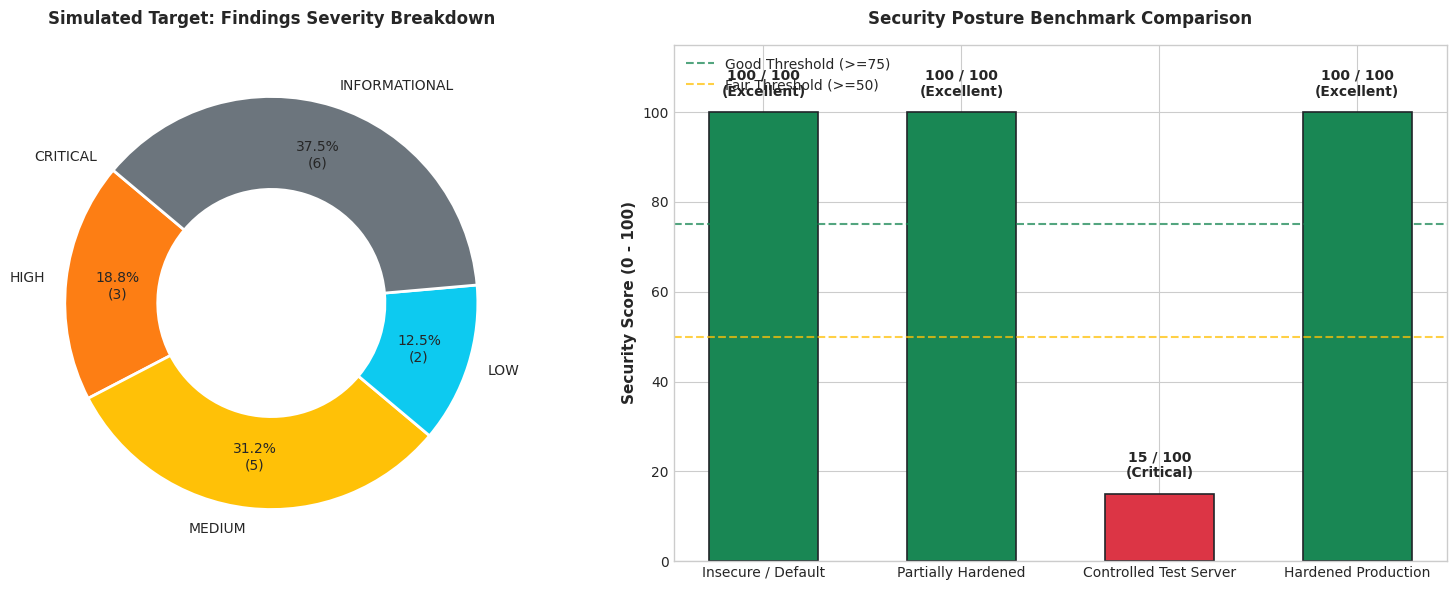

In [9]:
# Calculate scores for multiple comparative profiles
score_e2e_sim = calculate_score(scan_findings)
score_insecure_srv = calculate_score(execute_header_audit(profile_insecure) + cookie_findings_list[:2])
score_partial_srv = calculate_score(execute_header_audit(profile_partial) + cookie_findings_list[1:3])
score_hardened_srv = calculate_score(execute_header_audit(profile_hardened) + [cookie_findings_list[-1]])

profiles = ["Insecure / Default", "Partially Hardened", "Controlled Test Server", "Hardened Production"]
scores = [score_insecure_srv, score_partial_srv, score_e2e_sim, score_hardened_srv]

# Render 2-panel figure
fig, (ax_donut, ax_bar) = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Severity Breakdown Donut Chart
severity_order = ["CRITICAL", "HIGH", "MEDIUM", "LOW", "INFORMATIONAL"]
sev_counts = df_e2e_results["Severity"].value_counts().reindex(severity_order).fillna(0)
palette = ["#dc3545", "#fd7e14", "#ffc107", "#0dcaf0", "#6c757d"]

wedges, texts, autotexts = ax_donut.pie(
    sev_counts,
    labels=sev_counts.index,
    autopct=lambda pct: f"{pct:.1f}%\n({int(round(pct*sum(sev_counts)/100))})" if pct > 0 else "",
    startangle=140,
    colors=palette,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
    pctdistance=0.75
)
ax_donut.set_title("Simulated Target: Findings Severity Breakdown", fontsize=12, fontweight="bold", pad=15)

# Panel 2: Benchmark Score Comparison Bar Chart
bar_colors = ["#dc3545" if s < 50 else "#ffc107" if s < 75 else "#198754" for s in scores]
bars = ax_bar.bar(profiles, scores, color=bar_colors, width=0.55, edgecolor="#212529", linewidth=1.2)
ax_bar.set_ylim(0, 115)
ax_bar.set_ylabel("Security Score (0 - 100)", fontsize=11, fontweight="bold")
ax_bar.set_title("Security Posture Benchmark Comparison", fontsize=12, fontweight="bold", pad=15)
ax_bar.axhline(75, color="#198754", linestyle="--", linewidth=1.5, alpha=0.75, label="Good Threshold (>=75)")
ax_bar.axhline(50, color="#ffc107", linestyle="--", linewidth=1.5, alpha=0.75, label="Fair Threshold (>=50)")

for bar in bars:
    y = bar.get_height()
    lbl = f"{int(y)} / 100\n({score_label(int(y))})"
    ax_bar.text(bar.get_x() + bar.get_width() / 2, y + 3, lbl, ha="center", va="bottom", fontsize=10, fontweight="bold")

ax_bar.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 8. Experiment 7: Report Generation (JSON & CSV Export Simulation)

### Objective
Demonstrate how WebShield findings are compiled into standard, machine-readable JSON and CSV export formats for DevSecOps automated pipelines and audit records.


In [10]:
# Construct structured report payload mirroring services/report_service.py
report_payload = {
    "scan_summary": {
        "target_url": test_target_url,
        "security_score": score_e2e_sim,
        "rating_label": score_label(score_e2e_sim),
        "total_findings": len(scan_findings),
        "severity_distribution": {k.lower(): int(v) for k, v in sev_counts.items()}
    },
    "key_findings_sample": [
        {
            "finding_id": getattr(f, "finding_id", ""),
            "check_name": getattr(f, "check_name", ""),
            "category": getattr(f, "category", ""),
            "severity": getattr(f, "severity", ""),
            "status": getattr(f, "status", ""),
            "evidence": getattr(f, "evidence", "")
        }
        for f in scan_findings if getattr(f, "status", "").lower() in ("fail", "warning")
    ][:5]
}

print("=== Structured JSON Export Preview ===")
print(json.dumps(report_payload, indent=2))


=== Structured JSON Export Preview ===
{
  "scan_summary": {
    "target_url": "http://127.0.0.1:53888",
    "security_score": 15,
    "rating_label": "Critical",
    "total_findings": 16,
    "severity_distribution": {
      "critical": 0,
      "high": 3,
      "medium": 5,
      "low": 2,
      "informational": 6
    }
  },
  "key_findings_sample": [
    {
      "finding_id": "TLS-001",
      "check_name": "HTTPS Support",
      "category": "Transport Security",
      "severity": "high",
      "status": "fail",
      "evidence": "HTTPSConnectionPool(host='127.0.0.1', port=53888): Max retries exceeded with url: / (Caused by SSLError(SSLError(1, '[SSL: WRONG_VERSION_NUMBER] wrong version number (_ssl.c:1018)')))"
    },
    {
      "finding_id": "TLS-002",
      "check_name": "HTTP to HTTPS Redirect",
      "category": "Transport Security",
      "severity": "medium",
      "status": "fail",
      "evidence": "HTTP 200 with no redirect."
    },
    {
      "finding_id": "TLS-003",
   

## 9. Summary, Limitations & Ethical Guidelines

### Summary of Experimental Findings
1. **SSRF Guardrails:** Pre-flight IP parsing and CIDR checking completely neutralize SSRF risks against private LANs, loopbacks, and cloud metadata without dispatching network packets.
2. **Modular Audit Breadth:** WebShield accurately evaluates transport posture, defense headers, session cookie flags, CORS reflections, and plaintext form actions.
3. **Scoring Efficacy:** The deductive scoring algorithm maps directly to observed security risks, penalizing critical and high vulnerabilities while providing clear remediation advice.

### Genuine System Limitations
- **Single-Page Scope:** WebShield assesses the provided URL; it does not crawl entire web hierarchies recursively.
- **Static DOM Inspection:** HTML inspection relies on BeautifulSoup. Highly dynamic single-page applications (SPAs) rendering forms exclusively via client-side JavaScript may not expose all forms to static DOM inspection.
- **Contextual Exploitability:** Security header and cookie absence indicates posture weakness, not necessarily active exploitable compromise.

### Ethical Scanner Policy
- **Authorized Testing Only:** Never scan endpoints without documented, written authorization.
- **Non-Destructive Scanning:** WebShield strictly performs read-only inspection; it does not inject exploits, perform fuzzing, or conduct denial-of-service tests.

### References & Security Standards
1. OWASP Foundation. (2021). *OWASP Top 10 Web Application Security Risks*. https://owasp.org/Top10/
2. Internet Engineering Task Force (IETF). (2012). *HTTP Strict Transport Security (HSTS)* (RFC 6797).
3. Internet Engineering Task Force (IETF). (2011). *HTTP State Management Mechanism* (RFC 6265 / RFC 6265bis).
4. World Wide Web Consortium (W3C). (2020). *Content Security Policy Level 3*. https://www.w3.org/TR/CSP3/
5. Mozilla Developer Network (MDN). *Web Security Guidelines*. https://infosec.mozilla.org/guidelines/web_security
